# Домашнее задание "Корреляционный и регрессионный анализ"

Инструкции:
- Скачайте файл `practical_module_dataset.csv` и заполните ячейки с заданиями кодом и выводами.
- В каждой задаче требуется: короткая формулировка метода, код и расчёты, численные результаты (коэффициенты, статистики, p-value, CI, R^2) и краткий вывод (1-2 фразы).
- Разрешённые библиотеки: `numpy`, `pandas`, `scipy`, `statsmodels`, `scikit-learn`, `matplotlib`.
- Для воспроизводимости задан `np.random.seed` - не меняйте его.

Формат сдачи: .ipynb с заполненными ячейками, кодом и выводами.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor

np.random.seed(28)

In [2]:
df = pd.read_csv('practical_module_dataset.csv')
print(df.shape)
df.head()

(30, 8)


,id,age,height_cm,weight_kg,iq,tv_hours,study_hours,score
0,1,24,155.2,51.37,91,11,11.9,76.5
1,2,37,184.9,76.49,90,15,4.0,65.4
2,3,32,169.8,64.24,98,6,10.6,78.2
3,4,28,173.6,68.22,88,9,9.2,75.6
4,5,25,174.2,73.80,102,8,8.0,75.1


### Задание 1. Первичный анализ данных (EDA)

- Посмотрите на основные статистические показатели для **всех** переменных.
- Проверьте типы данных и наличие пропусков.
- Постройте гистограммы числовых признаков.
- Запишите наблюдения в текстовой ячейке.

,count,mean,std,min,25%,50%,75%,max
id,30.0,15.500000,8.803408,1.00,8.2500,15.500,22.7500,30.00
age,30.0,29.400000,6.672641,18.00,24.2500,29.000,35.5000,39.00
height_cm,30.0,169.153333,9.584101,148.20,163.2500,169.750,174.1000,185.80
weight_kg,30.0,62.734000,9.201488,44.75,56.6225,63.675,68.6025,81.13
iq,30.0,100.433333,12.119188,82.00,91.0000,97.000,109.7500,132.00
tv_hours,30.0,12.266667,3.832109,6.00,9.0000,12.000,14.0000,22.00
study_hours,30.0,7.640000,3.281568,2.70,4.9750,7.650,9.4500,14.40
score,30.0,73.400000,8.253693,58.90,67.8000,74.300,78.7250,91.50


id               int64
age              int64
height_cm      float64
weight_kg      float64
iq               int64
tv_hours         int64
study_hours    float64
score          float64
dtype: object

Пропуски по столбцам:
id             0
age            0
height_cm      0
weight_kg      0
iq             0
tv_hours       0
study_hours    0
score          0
dtype: int64
Дубликатов id: 0

Коэффициент асимметрии (skew):
age           -0.085
height_cm     -0.274
weight_kg     -0.092
iq             0.880
tv_hours       0.884
study_hours    0.205
score          0.145
dtype: float64


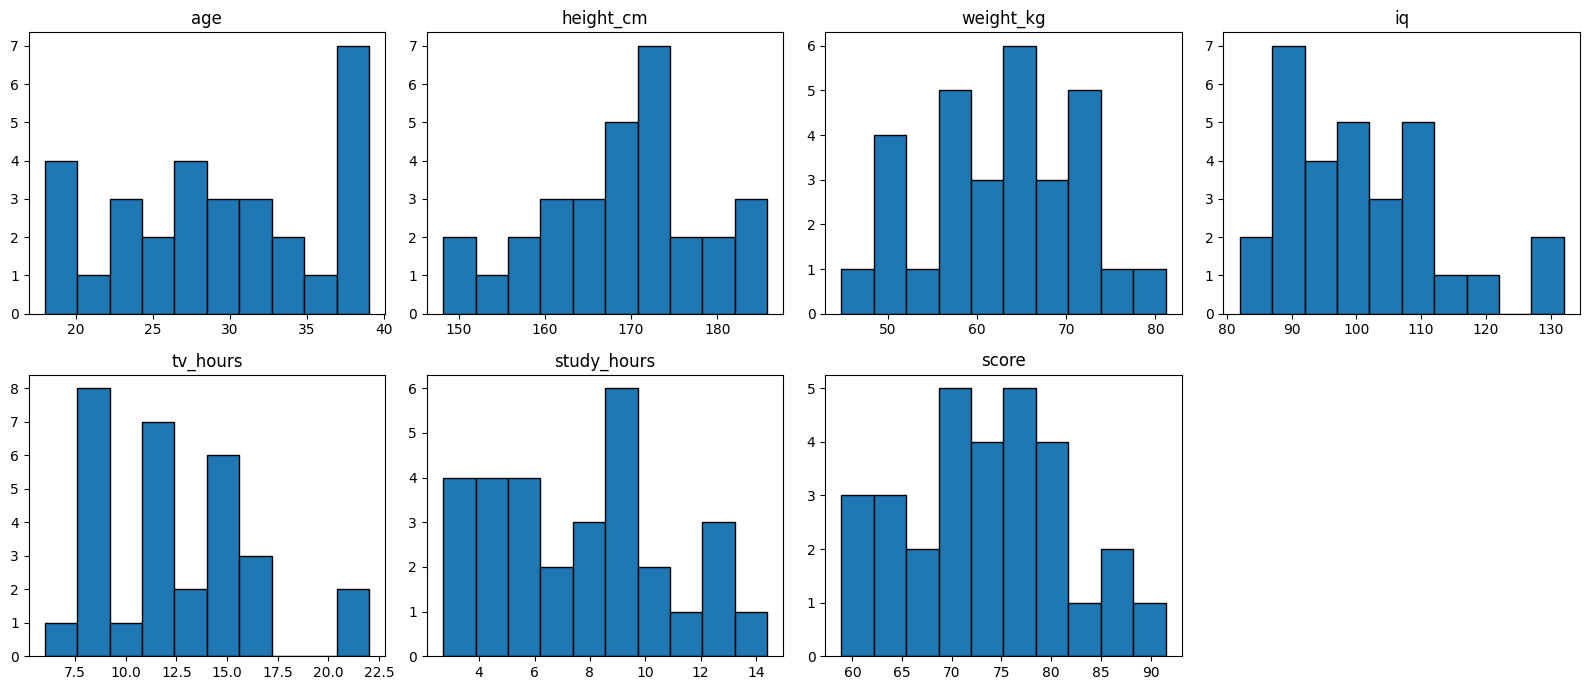

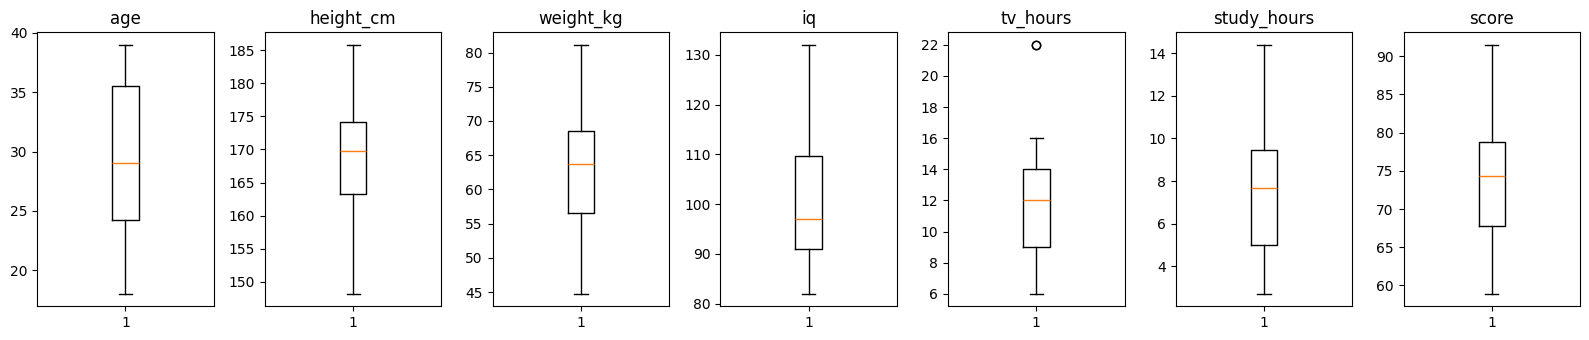

age: выбросов 0 
height_cm: выбросов 0 
weight_kg: выбросов 0 
iq: выбросов 0 
tv_hours: выбросов 2 [np.int64(22), np.int64(22)]
study_hours: выбросов 0 
score: выбросов 0 


In [3]:
# Описательные статистики по всем переменным
display(df.describe().T)

# Типы данных и пропуски
print(df.dtypes)
print('\nПропуски по столбцам:')
print(df.isna().sum())
print('Дубликатов id:', df['id'].duplicated().sum())

# Асимметрия числовых признаков (id исключаем — это идентификатор)
num_cols = ['age', 'height_cm', 'weight_kg', 'iq', 'tv_hours', 'study_hours', 'score']
print('\nКоэффициент асимметрии (skew):')
print(df[num_cols].skew().round(3))

# Гистограммы
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), num_cols):
    ax.hist(df[col], bins=10, edgecolor='black')
    ax.set_title(col)
axes.ravel()[-1].axis('off')
plt.tight_layout()
plt.show()

# Ящики с усами для поиска выбросов
fig, axes = plt.subplots(1, len(num_cols), figsize=(16, 3.5))
for ax, col in zip(axes, num_cols):
    ax.boxplot(df[col])
    ax.set_title(col)
plt.tight_layout()
plt.show()

# Выбросы по правилу 1.5*IQR
for col in num_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    out = df[(df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)][col]
    print(f'{col}: выбросов {len(out)}', list(out.values) if len(out) else '')

**Вывод:** В данных 30 наблюдений и 8 столбцов. Все столбцы числовые (int64/float64), пропусков и дубликатов нет. `age`, `height_cm`, `weight_kg`, `study_hours` и `score` распределены примерно симметрично (|skew| < 0.3). У `iq` и `tv_hours` заметная правосторонняя асимметрия (skew ≈ 0.88): в `tv_hours` по правилу 1.5·IQR есть 2 выброса (22 часа), в `iq` длинный правый хвост (до 132), но формальных выбросов нет. Выборка маленькая, поэтому гистограммы шумные.

### Задание 2. Связь height_cm и weight_kg

- Постройте scatter plot по признакам `height_cm` и `weight_kg`.
- Посчитайте коэффициент Пирсона и p-value.
- Интерпретируйте силу, направление и значимость связи в выводе.

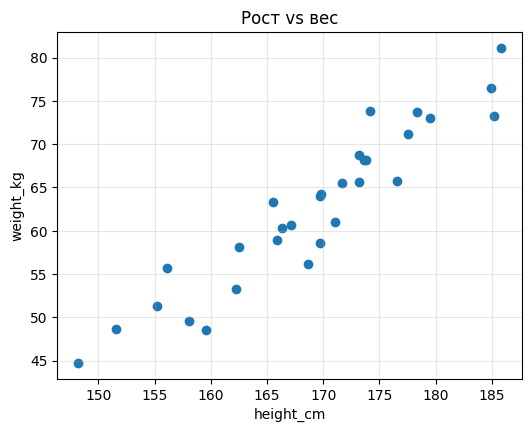

Коэффициент Пирсона r = 0.9435
p-value = 5.799e-15


In [4]:
plt.figure(figsize=(6, 4.5))
plt.scatter(df['height_cm'], df['weight_kg'])
plt.xlabel('height_cm')
plt.ylabel('weight_kg')
plt.title('Рост vs вес')
plt.grid(alpha=0.3)
plt.show()

r, p = stats.pearsonr(df['height_cm'], df['weight_kg'])
print(f'Коэффициент Пирсона r = {r:.4f}')
print(f'p-value = {p:.3e}')

**Вывод:** r ≈ 0.944, p-value ≈ 5.8e-15. Связь между ростом и весом положительная (чем выше человек, тем больше вес), очень сильная (|r| > 0.9) и статистически значимая: p-value много меньше 0.05, нулевая гипотеза об отсутствии корреляции отвергается. На scatter plot точки лежат близко к прямой, так что связь близка к линейной.

### Задание 3. Связь tv_hours и iq

- Посчитайте ранговый коэффициент Спирмена между `tv_hours` и `iq` и p-value.
- Оцените, есть ли монотонная связь в выводе.

In [5]:
rs, p_s = stats.spearmanr(df['tv_hours'], df['iq'])
print(f'Коэффициент Спирмена rs = {rs:.4f}')
print(f'p-value = {p_s:.4f}')

Коэффициент Спирмена rs = -0.2108
p-value = 0.2635


**Вывод:** rs ≈ −0.211, p-value ≈ 0.264 > 0.05. Направление связи отрицательное и слабое, но статистически незначимое: на этой выборке нельзя утверждать, что между часами у телевизора и IQ есть монотонная связь.

### Задание 4. Простая линейная регрессия weight_kg ~ height_cm

- Постройте регрессию, найдите intercept и slope, 95% доверительный интервал для наклона.
- Интерпретируйте результат в выводе.

In [6]:
X = sm.add_constant(df['height_cm'])
y = df['weight_kg']
model_w = sm.OLS(y, X).fit()
print(model_w.summary())

intercept, slope = model_w.params
ci_low, ci_high = model_w.conf_int(alpha=0.05).loc['height_cm']
print(f'\nIntercept = {intercept:.4f}')
print(f'Slope = {slope:.4f}')
print(f'95% CI для наклона: [{ci_low:.4f}; {ci_high:.4f}]')
print(f'R^2 = {model_w.rsquared:.4f}')

                            OLS Regression Results                            
Dep. Variable:              weight_kg   R-squared:                       0.890
Model:                            OLS   Adj. R-squared:                  0.886
Method:                 Least Squares   F-statistic:                     227.1
Date:                Wed, 11 Nov 2026   Prob (F-statistic):           5.80e-15
Time:                        14:24:04   Log-Likelihood:                -75.497
No. Observations:                  30   AIC:                             155.0
Df Residuals:                      28   BIC:                             157.8
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        -90.4962     10.183     -8.887      0.0

**Вывод:** Уравнение: weight = −90.50 + 0.906·height. Наклон 0.906: каждый дополнительный сантиметр роста в среднем добавляет ≈ 0.91 кг веса. 95% CI для наклона [0.783; 1.029] не содержит 0, значит эффект значим (p < 0.001): с вероятностью 95% истинный прирост составляет от 0.78 до 1.03 кг на 1 см. R² ≈ 0.89, то есть рост объясняет 89% вариации веса. Отрицательный intercept не имеет физического смысла (рост 0 см лежит далеко за пределами данных), это просто параметр сдвига прямой.

### Задание 5. Прогноз и предсказательный интервал

- Для `height_cm = 175` вычислите точечный прогноз веса и 95% предсказательный интервал для нового наблюдения.

In [7]:
x_new = pd.DataFrame({'const': [1.0], 'height_cm': [175.0]})
pred = model_w.get_prediction(x_new).summary_frame(alpha=0.05)
print(pred.round(3))

print(f"\nТочечный прогноз веса при росте 175 см: {pred['mean'].iloc[0]:.2f} кг")
print(f"95% доверительный интервал для среднего: [{pred['mean_ci_lower'].iloc[0]:.2f}; {pred['mean_ci_upper'].iloc[0]:.2f}] кг")
print(f"95% предсказательный интервал для нового наблюдения: [{pred['obs_ci_lower'].iloc[0]:.2f}; {pred['obs_ci_upper'].iloc[0]:.2f}] кг")

    mean  mean_se  mean_ci_lower  mean_ci_upper  obs_ci_lower  obs_ci_upper
0  68.03    0.667         66.665         69.396        61.531         74.53

Точечный прогноз веса при росте 175 см: 68.03 кг
95% доверительный интервал для среднего: [66.66; 69.40] кг
95% предсказательный интервал для нового наблюдения: [61.53; 74.53] кг


**Вывод:** Для человека ростом 175 см прогнозируемый вес ≈ 68.0 кг. 95% предсказательный интервал для нового наблюдения: [61.5; 74.5] кг, то есть вес конкретного нового человека такого роста с вероятностью 95% попадёт в этот диапазон. Он заметно шире доверительного интервала для среднего веса [66.7; 69.4] кг, потому что кроме неопределённости оценки линии учитывает индивидуальный разброс (дисперсию остатков).

### Задание 6. Множественная регрессия

- Постройте модель score `~ study_hours + iq + tv_hours + age`.
- Выведите R^2 и оцените значимость предикторов по p-value.
- Дополнительно проверьте мультиколлинеарность через VIF.
- Запшите наблюдения в выводе.

In [8]:
features = ['study_hours', 'iq', 'tv_hours', 'age']
X_m = sm.add_constant(df[features])
y_m = df['score']
model_s = sm.OLS(y_m, X_m).fit()
print(model_s.summary())

res = pd.DataFrame({'coef': model_s.params, 'p_value': model_s.pvalues})
res['значим (α=0.05)'] = res['p_value'] < 0.05
print('\n', res.round(4))
print(f'\nR^2 = {model_s.rsquared:.4f}, adj. R^2 = {model_s.rsquared_adj:.4f}')
print(f'F-статистика = {model_s.fvalue:.2f}, p-value = {model_s.f_pvalue:.3e}')

# VIF (константу включаем в матрицу, но для неё VIF не интерпретируем)
vif = pd.DataFrame({
    'feature': features,
    'VIF': [variance_inflation_factor(X_m.values, i) for i in range(1, X_m.shape[1])]
})
print('\n', vif.round(3))

                            OLS Regression Results                            
Dep. Variable:                  score   R-squared:                       0.874
Model:                            OLS   Adj. R-squared:                  0.854
Method:                 Least Squares   F-statistic:                     43.38
Date:                Wed, 11 Nov 2026   Prob (F-statistic):           6.73e-11
Time:                        14:24:04   Log-Likelihood:                -74.299
No. Observations:                  30   AIC:                             158.6
Df Residuals:                      25   BIC:                             165.6
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const          45.6584      6.807      6.708      

**Вывод:** Модель в целом значима (F = 43.4, p ≈ 6.7e-11). R² = 0.874 (adj. R² = 0.854): модель объясняет ≈ 87% дисперсии `score`. При α = 0.05 значимы `study_hours` (+2.10 балла за каждый час учёбы, p < 0.001) и `iq` (+0.15 балла за пункт IQ, p ≈ 0.010). `tv_hours` (p ≈ 0.37) и `age` (p ≈ 0.61) незначимы, их можно исключить из модели. Все VIF ≈ 1.1–1.2 (< 5), мультиколлинеарности нет. Большой condition number в summary объясняется масштабом признаков (IQ ~100) и наличием константы, а не коллинеарностью.

### Задание 7. Ошибка модели

- Оцените типичную ошибку предсказаний модели из задания 6: вычислите RMSE (корень из средней квадратичной ошибки) на всей выборке и сравните её с разбросом целевой переменной (стандартным отклонением score).
- Насколько модель уменьшает типичную ошибку?

In [9]:
y_pred = model_s.predict(X_m)
rmse = np.sqrt(np.mean((y_m - y_pred) ** 2))
std_y = y_m.std(ddof=0)   # RMSE "константной" модели (прогноз средним)
std_y1 = y_m.std(ddof=1)

print(f'RMSE модели = {rmse:.3f}')
print(f'Стандартное отклонение score = {std_y:.3f} (ddof=0), {std_y1:.3f} (ddof=1)')
print(f'Снижение типичной ошибки: {(1 - rmse / std_y) * 100:.1f}%')
print(f'Проверка: 1 - (RMSE/std)^2 = {1 - (rmse / std_y) ** 2:.4f} = R^2 = {model_s.rsquared:.4f}')

RMSE модели = 2.880
Стандартное отклонение score = 8.115 (ddof=0), 8.254 (ddof=1)
Снижение типичной ошибки: 64.5%
Проверка: 1 - (RMSE/std)^2 = 0.8741 = R^2 = 0.8741


**Вывод:** RMSE модели ≈ 2.88 балла при стандартном отклонении `score` ≈ 8.1 балла (это ошибка наивного прогноза средним). Модель уменьшает типичную ошибку примерно на 64.5%, почти в 3 раза. Это согласуется с R² ≈ 0.87, так как 1 − (RMSE/σ)² = R². Оценка сделана на обучающей выборке, поэтому она оптимистична.

### Задание 8. Градиентный спуск

- Реализуйте градиентный спуск для простой регрессии score `~ study_hours` и сравните коэффициенты со `statsmodels`.
- Ответьте на вопрос: возможно ли получить метрику алгоритмом градиентного спуска лучше, чем у МНК?

Параметры GD: lr = 0.01, итераций = 20000
GD : intercept = 56.0340, slope = 2.2730, MSE = 12.0689
OLS: intercept = 56.0340, slope = 2.2730, MSE = 12.0689
Разница: |Δintercept| = 1.15e-12, |Δslope| = 1.31e-13


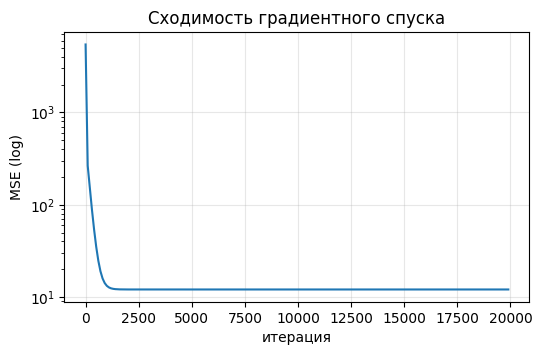

In [10]:
x = df['study_hours'].values
y = df['score'].values
n = len(x)

# Параметры градиентного спуска
lr = 0.01        # скорость обучения
n_iter = 20000   # число итераций
b0, b1 = 0.0, 0.0  # начальные значения: свободный член и наклон
history = []

for i in range(n_iter):
    y_hat = b0 + b1 * x
    err = y_hat - y
    grad_b0 = 2 / n * err.sum()
    grad_b1 = 2 / n * (err * x).sum()
    b0 -= lr * grad_b0
    b1 -= lr * grad_b1
    if i % 100 == 0:
        history.append(np.mean(err ** 2))

mse_gd = np.mean((b0 + b1 * x - y) ** 2)

# OLS через statsmodels
ols = sm.OLS(y, sm.add_constant(x)).fit()
mse_ols = np.mean(ols.resid ** 2)

print(f'Параметры GD: lr = {lr}, итераций = {n_iter}')
print(f'GD : intercept = {b0:.4f}, slope = {b1:.4f}, MSE = {mse_gd:.4f}')
print(f'OLS: intercept = {ols.params[0]:.4f}, slope = {ols.params[1]:.4f}, MSE = {mse_ols:.4f}')
print(f'Разница: |Δintercept| = {abs(b0 - ols.params[0]):.2e}, |Δslope| = {abs(b1 - ols.params[1]):.2e}')

plt.figure(figsize=(6, 3.5))
plt.plot(np.arange(len(history)) * 100, history)
plt.yscale('log')
plt.xlabel('итерация')
plt.ylabel('MSE (log)')
plt.title('Сходимость градиентного спуска')
plt.grid(alpha=0.3)
plt.show()

**Вывод:** Градиентный спуск (lr = 0.01, 20 000 итераций, старт из нуля, со свободным членом) сошёлся к intercept = 56.034, slope = 2.273, что совпадает с OLS до ~1e-12. MSE тоже совпадает (12.069). Получить MSE на обучающей выборке лучше, чем у МНК, градиентным спуском **нельзя**: МНК даёт точный глобальный минимум выпуклой квадратичной функции потерь, а GD может к нему только приблизиться. Лучше выйти может только другая метрика (например, MAE) или ошибка на новых данных при другой постановке задачи (регуляризация, ранняя остановка).

### Задание 9. Бутстрэп-интервал для корреляции

- Постройте бутстрэп-оценку 95% доверительного интервала для коэффициента Пирсона между `height_cm` и `weight_kg` (1000 бутстрэп-итераций, перцентильный метод).

Исходный r = 0.9435
Бутстрэп: среднее r = 0.9436
95% бутстрэп-CI (перцентильный): [0.9021; 0.9705]


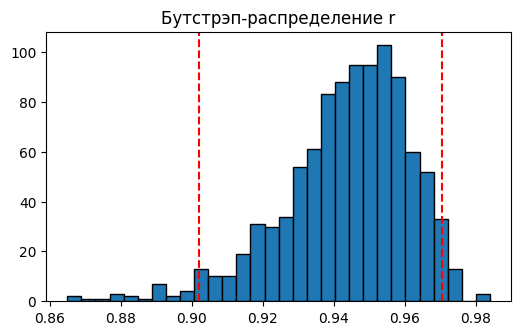

In [11]:
n_boot = 1000
h = df['height_cm'].values
w = df['weight_kg'].values
n = len(df)

boot_r = np.empty(n_boot)
for i in range(n_boot):
    idx = np.random.randint(0, n, n)  # выборка с возвращением
    boot_r[i] = np.corrcoef(h[idx], w[idx])[0, 1]

ci_l, ci_u = np.percentile(boot_r, [2.5, 97.5])
print(f'Исходный r = {np.corrcoef(h, w)[0, 1]:.4f}')
print(f'Бутстрэп: среднее r = {boot_r.mean():.4f}')
print(f'95% бутстрэп-CI (перцентильный): [{ci_l:.4f}; {ci_u:.4f}]')

plt.figure(figsize=(6, 3.5))
plt.hist(boot_r, bins=30, edgecolor='black')
plt.axvline(ci_l, color='red', ls='--')
plt.axvline(ci_u, color='red', ls='--')
plt.title('Бутстрэп-распределение r')
plt.show()

**Вывод:** По 1000 бутстрэп-репликациям (перцентильный метод) 95% CI для коэффициента Пирсона между ростом и весом равен ≈ [0.902; 0.971]. Интервал целиком выше 0.9 и далеко от нуля, что подтверждает очень сильную положительную связь из задания 2. Интервал несимметричен относительно r = 0.944, как и положено для корреляции вблизи 1.

### Задание 10. Диагностика остатков

Для модели из задания 6 проведите диагностику остатков:
- постройте график остатков против предсказанных значений,
- QQ-plot остатков и гистограмму остатков.

Сделайте вывод о выполнении предпосылок регрессии.

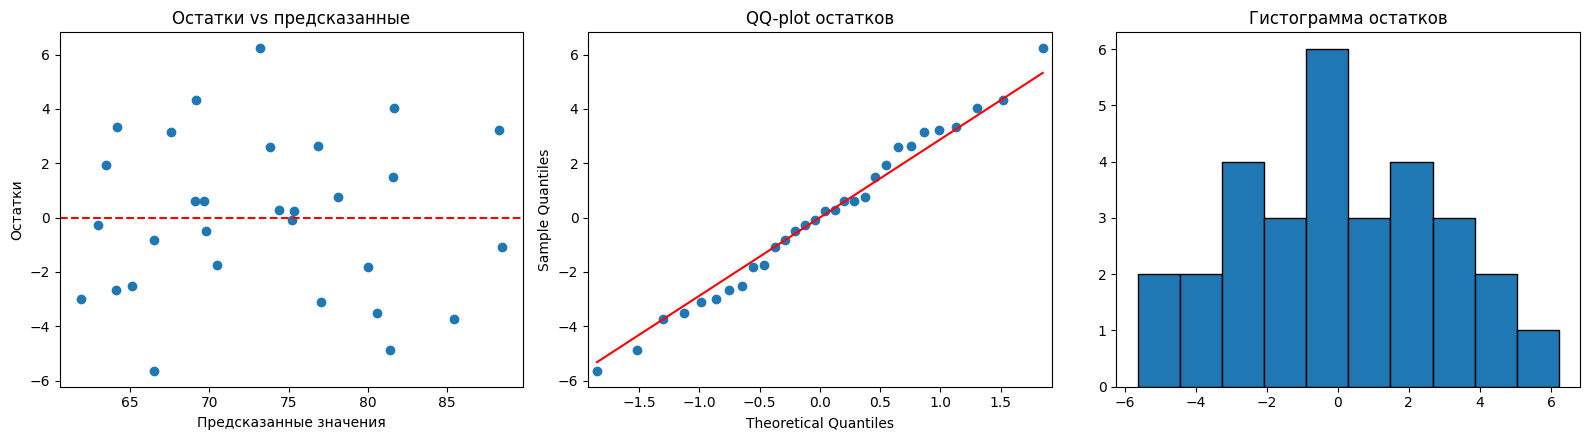

Шапиро-Уилк: W = 0.9866, p-value = 0.9616
Бройш-Паган: LM p-value = 0.9886
Дарбин-Уотсон = 2.303
Среднее остатков = 1.12e-13


In [12]:
fitted = model_s.fittedvalues
resid = model_s.resid

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].scatter(fitted, resid)
axes[0].axhline(0, color='red', ls='--')
axes[0].set_xlabel('Предсказанные значения')
axes[0].set_ylabel('Остатки')
axes[0].set_title('Остатки vs предсказанные')

sm.qqplot(resid, line='s', ax=axes[1])
axes[1].set_title('QQ-plot остатков')

axes[2].hist(resid, bins=10, edgecolor='black')
axes[2].set_title('Гистограмма остатков')
plt.tight_layout()
plt.show()

# Формальные проверки
sw_stat, sw_p = stats.shapiro(resid)
print(f'Шапиро-Уилк: W = {sw_stat:.4f}, p-value = {sw_p:.4f}')
from statsmodels.stats.diagnostic import het_breuschpagan
bp = het_breuschpagan(resid, X_m)
print(f'Бройш-Паган: LM p-value = {bp[1]:.4f}')
from statsmodels.stats.stattools import durbin_watson
print(f'Дарбин-Уотсон = {durbin_watson(resid):.3f}')
print(f'Среднее остатков = {resid.mean():.2e}')

**Вывод:** На графике остатков против предсказанных точки разбросаны случайно вокруг 0, без воронки и без нелинейного паттерна, поэтому линейность и гомоскедастичность выполняются (тест Бройша–Пагана p ≈ 0.99). На QQ-plot точки лежат близко к прямой, гистограмма без сильной асимметрии, тест Шапиро–Уилка p ≈ 0.96: нормальность остатков не отвергается. Среднее остатков ≈ 0, статистика Дарбина–Уотсона ≈ 2.3, значимой автокорреляции нет. Предпосылки линейной регрессии в целом выполнены, с поправкой на малый объём выборки (n = 30).